# Лабораторная работа 3. Шум, фильтрация, пороговая и морфологическая обработка

Сначала строим ядро Гаусса вручную и сравниваем с OpenCV, затем добавляем два вида шума,
сравниваем три фильтра, получаем маски линий и цифр и очищаем адаптивную маску.
Все изображения показываются на одинаковой шкале яркости `vmin=0, vmax=255`.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# Ищем папку с image.png, чтобы ноутбук запускался и из lab3, и из корня репозитория.
HERE = Path.cwd()
if not (HERE / "image.png").exists():
    HERE = next(p for p in (HERE, HERE / "lab3") if (p / "image.png").exists())
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
RNG = np.random.default_rng(42)

## 1. Чтение изображения

Снимок читается в оттенках серого и не изменяется: исходный массив `gray`
понадобится для сравнения со всеми результатами фильтрации.

Размер: 558x563, тип: uint8


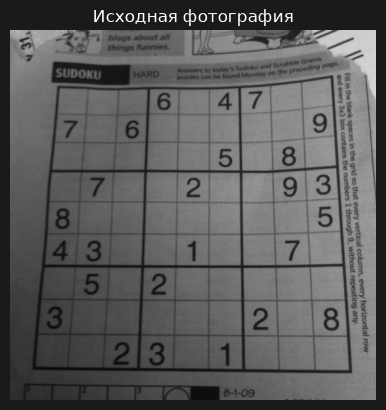

In [2]:
gray = cv.imread(str(HERE / "image.png"), cv.IMREAD_GRAYSCALE)
if gray is None:
    raise ValueError("Не удалось открыть image.png")

print(f"Размер: {gray.shape[1]}x{gray.shape[0]}, тип: {gray.dtype}")
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Исходная фотография")
plt.axis("off")
plt.show()

## 2. Собственные ядра Гаусса

Для окна `k x k` координаты `u, v` отсчитываются от центра: `-r ... r`, где `r = k // 2`.
Ненормированный вес равен `exp(-(u^2 + v^2) / (2 * sigma^2))`, затем все веса делятся на их сумму.
Постоянный множитель плотности Гаусса не нужен — при нормировке он сокращается.

In [3]:
def gaussian_kernel(size: int, sigma: float) -> np.ndarray:
    """Нормированное гауссово ядро size x size в float64."""
    radius = size // 2
    coords = np.arange(-radius, radius + 1, dtype=np.float64)
    u, v = np.meshgrid(coords, coords)
    kernel = np.exp(-(u * u + v * v) / (2.0 * sigma * sigma))
    return kernel / kernel.sum()


kernels = {(size, sigma): gaussian_kernel(size, sigma)
           for size in (3, 5, 7) for sigma in (1, 2)}

np.set_printoptions(precision=8, suppress=True)
for size in (3, 5, 7):
    kernel = kernels[(size, 1)]
    print(f"Ядро {size}x{size}, sigma=1:")
    print(kernel)
    print(f"Сумма элементов: {kernel.sum():.16f}")
    symmetric = np.allclose(kernel, kernel[::-1, ::-1]) and np.allclose(kernel, kernel.T)
    print(f"Симметрично относительно центра: {symmetric}\n")

Ядро 3x3, sigma=1:
[[0.07511361 0.1238414  0.07511361]
 [0.1238414  0.20417996 0.1238414 ]
 [0.07511361 0.1238414  0.07511361]]
Сумма элементов: 0.9999999999999998
Симметрично относительно центра: True

Ядро 5x5, sigma=1:
[[0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.02193823 0.09832033 0.16210282 0.09832033 0.02193823]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]]
Сумма элементов: 1.0000000000000000
Симметрично относительно центра: True

Ядро 7x7, sigma=1:
[[0.00001965 0.00023941 0.00107296 0.00176901 0.00107296 0.00023941
  0.00001965]
 [0.00023941 0.0029166  0.01307131 0.02155094 0.01307131 0.0029166
  0.00023941]
 [0.00107296 0.01307131 0.05858154 0.09658463 0.05858154 0.01307131
  0.00107296]
 [0.00176901 0.02155094 0.09658463 0.15924113 0.09658463 0.02155094
  0.00176901]
 [0.00107296 0.01307131 0.05858154 0.09658463 0.05858154 0.0130713

## 3. Собственная фильтрация

Для каждого внутреннего пикселя берём окно соседей из **исходного** массива `I` и считаем
сумму произведений яркостей на веса ядра. Краевую полосу шириной `r` не трогаем —
она остаётся такой же, как в исходнике, поэтому дополнять изображение не нужно.

In [4]:
def manual_gaussian(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Фильтрация сверткой; краевая полоса шириной r остается как в исходнике."""
    source = image.astype(np.float64)
    result = source.copy()
    radius = kernel.shape[0] // 2
    height, width = source.shape
    for row in range(radius, height - radius):
        for col in range(radius, width - radius):
            window = source[row - radius:row + radius + 1, col - radius:col + radius + 1]
            result[row, col] = np.sum(window * kernel)
    return result

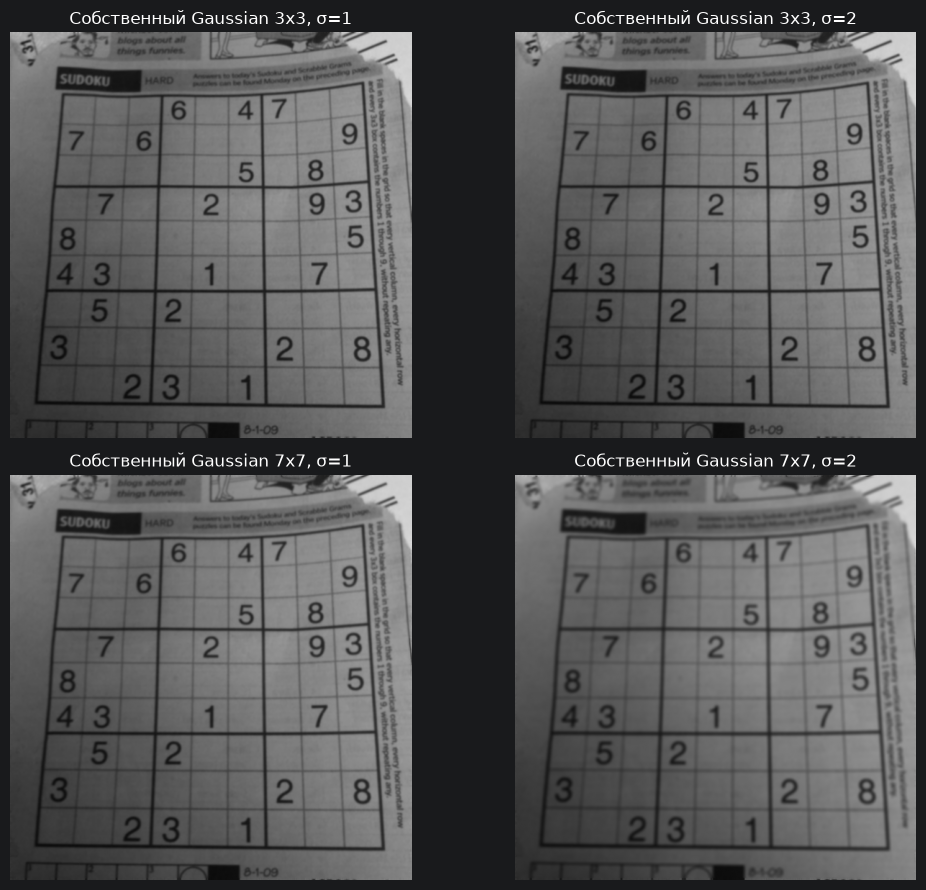

In [5]:
custom_results = []
for size, sigma in ((3, 1), (3, 2), (7, 1), (7, 2)):
    result = manual_gaussian(gray, kernels[(size, sigma)])
    custom_results.append((size, sigma, result))
    saved = np.clip(np.rint(result), 0, 255).astype(np.uint8)
    cv.imwrite(str(OUT / f"gaussian_manual_{size}_{sigma}.png"), saved)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (size, sigma, result) in zip(axes.flat, custom_results):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Собственный Gaussian {size}x{size}, σ={sigma}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Сравнение с OpenCV

`cv.GaussianBlur` получает ту же вещественную копию, то же окно и одинаковые `sigmaX`/`sigmaY`.
Сравниваем только внутреннюю область: OpenCV обрабатывает и краевые пиксели,
подставляя значения за границами, поэтому оставленная исходная краевая полоса
закономерно отличается.

In [6]:
height, width = gray.shape
print("Максимальная разница с OpenCV (только внутренние пиксели):")
for size, sigma, custom in custom_results:
    reference = cv.GaussianBlur(gray.astype(np.float64), (size, size), sigma, sigmaY=sigma)
    r = size // 2
    difference = np.abs(custom[r:height - r, r:width - r]
                        - reference[r:height - r, r:width - r])
    print(f"Окно {size}x{size}, σ={sigma}: {difference.max():.12g}")

Максимальная разница с OpenCV (только внутренние пиксели):
Окно 3x3, σ=1: 1.13686837722e-13
Окно 3x3, σ=2: 1.13686837722e-13
Окно 7x7, σ=1: 1.42108547152e-13
Окно 7x7, σ=2: 1.42108547152e-13


## 5. Два вида шума

Гауссовский шум: среднее 0, стандартное отклонение 20 уровней.
Сложение выполняется в `float64`, затем округление и ограничение 0–255;
прибавлять шум к `uint8` нельзя из-за отрицательных значений и переполнения.

Импульсный шум: каждый пиксель с вероятностью 2% становится чёрным и с вероятностью 2% — белым.
Каждая шумная копия создаётся один раз и используется во всех сравнениях.

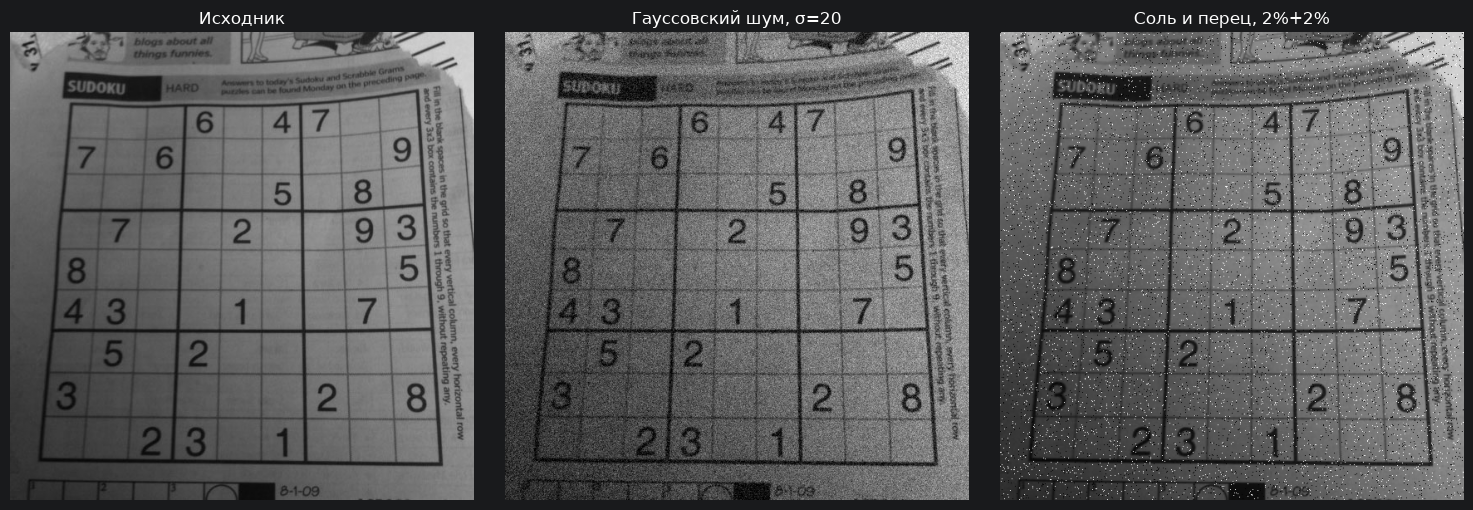

In [7]:
gaussian_noisy = np.clip(
    np.rint(gray.astype(np.float64) + RNG.normal(0, 20, gray.shape)), 0, 255
).astype(np.uint8)

p = 0.04
u = RNG.random(gray.shape)
impulse_noisy = gray.copy()
impulse_noisy[u < p / 2] = 0
impulse_noisy[u >= 1 - p / 2] = 255

cv.imwrite(str(OUT / "gaussian_noisy.png"), gaussian_noisy)
cv.imwrite(str(OUT / "impulse_noisy.png"), impulse_noisy)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, image) in zip(axes, [
        ("Исходник", gray),
        ("Гауссовский шум, σ=20", gaussian_noisy),
        ("Соль и перец, 2%+2%", impulse_noisy)]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Сравнение трёх фильтров

К каждой шумной копии независимо применяются среднее, гауссово и медианное сглаживание
с окном 5x5 (σ=1 для гауссова ядра). Результат одного фильтра не передаётся в следующий.

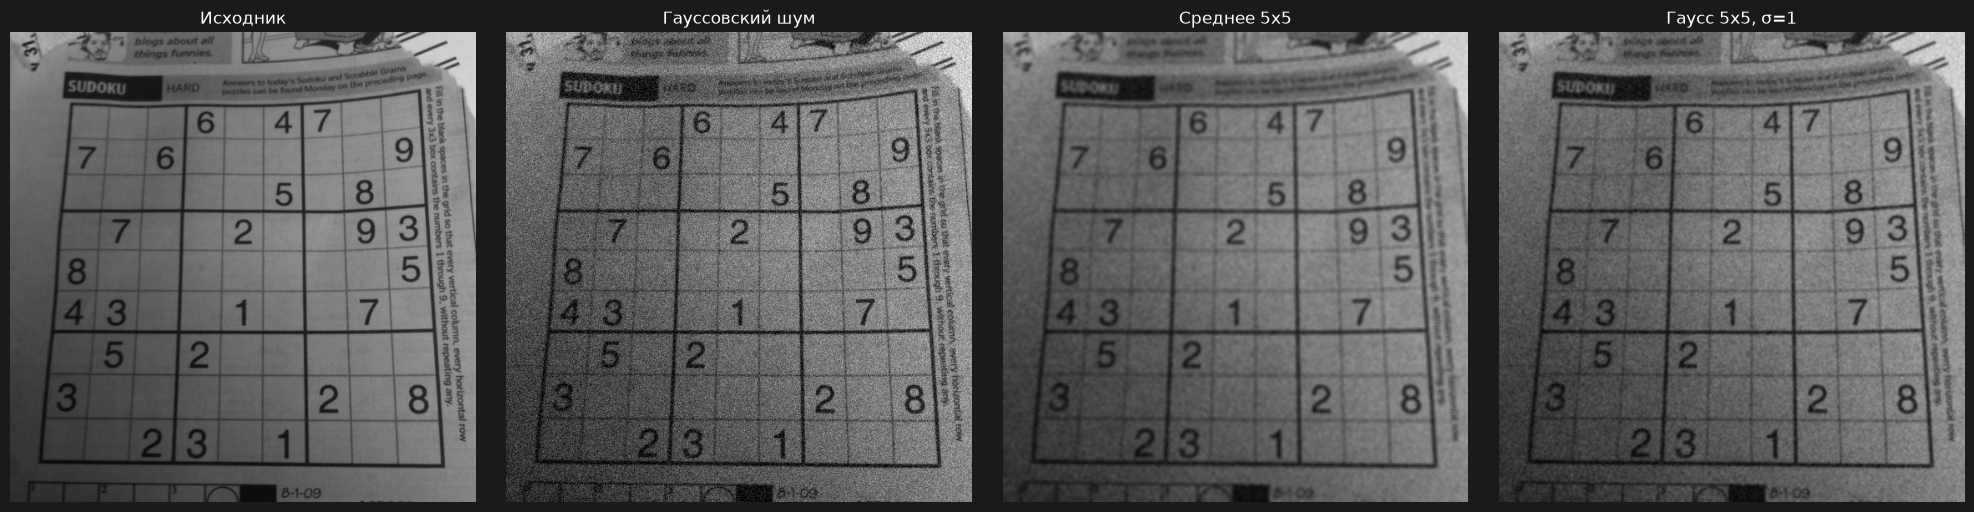

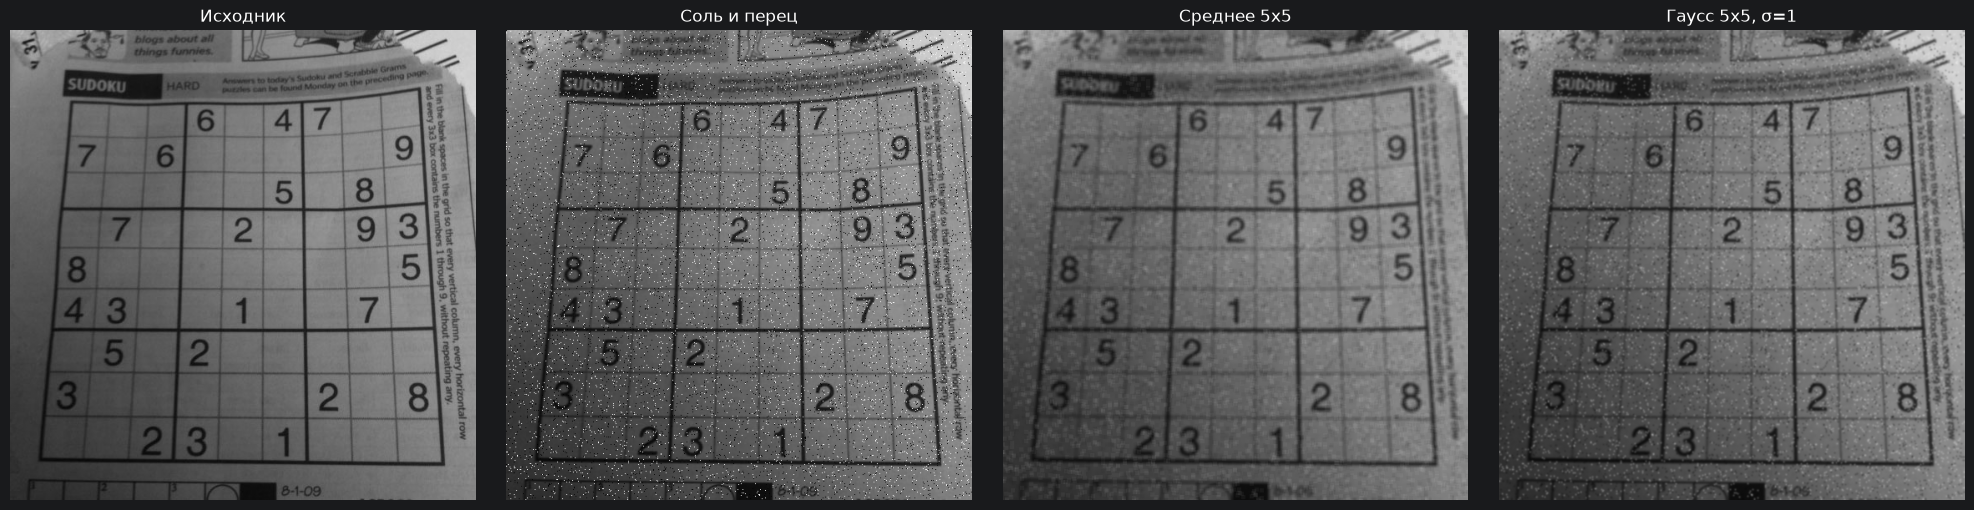

In [8]:
filtered_by_noise = {}
for noise_name, noisy in (("Гауссовский шум", gaussian_noisy), ("Соль и перец", impulse_noisy)):
    filtered_by_noise[noise_name] = {
        "Среднее 5x5": cv.blur(noisy, (5, 5)),
        "Гаусс 5x5, σ=1": cv.GaussianBlur(noisy, (5, 5), 1),
        "Медиана 5x5": cv.medianBlur(noisy, 5),
    }

for noise_name, noisy in (("Гауссовский шум", gaussian_noisy), ("Соль и перец", impulse_noisy)):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    panels = [("Исходник", gray), (noise_name, noisy), *filtered_by_noise[noise_name].items()]
    for ax, (title, image) in zip(axes, panels):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 7. MSE относительно исходника

MSE усредняет квадраты разностей яркостей по всему изображению.
Разность вычисляется после перевода в `float64`.
Сравнение с ошибкой собственной реализации из п. 4 некорректно: там проверялись
два способа расчёта только во внутренней области.

In [9]:
def mse(reference: np.ndarray, result: np.ndarray) -> float:
    difference = reference.astype(np.float64) - result.astype(np.float64)
    return float(np.mean(difference ** 2))


mse_values = {"Гауссовский шум": mse(gray, gaussian_noisy),
              "Соль и перец": mse(gray, impulse_noisy)}
for noise_name, results in filtered_by_noise.items():
    for filter_name, image in results.items():
        mse_values[f"{noise_name} — {filter_name}"] = mse(gray, image)

for label, value in mse_values.items():
    print(f"{label:42s} {value:9.4f}")

Гауссовский шум                             396.9386
Соль и перец                                727.2279
Гауссовский шум — Среднее 5x5                82.7460
Гауссовский шум — Гаусс 5x5, σ=1             55.8065
Гауссовский шум — Медиана 5x5                76.5114
Соль и перец — Среднее 5x5                  101.7796
Соль и перец — Гаусс 5x5, σ=1                88.3732
Соль и перец — Медиана 5x5                   38.5807


## 8. Маски линий и цифр

Работаем с копией, испорченной импульсным шумом: сначала медианный фильтр 5x5,
затем три способа пороговой обработки. Используется обратный порог `BINARY_INV`,
чтобы тёмные линии и цифры стали белыми объектами на чёрном фоне.

В адаптивном методе окно 31x31 шире тонких штрихов и учитывает местную яркость бумаги;
порог равен взвешенной по Гауссу средней яркости в окне минус 5 уровней.

Порог Оцу: 97


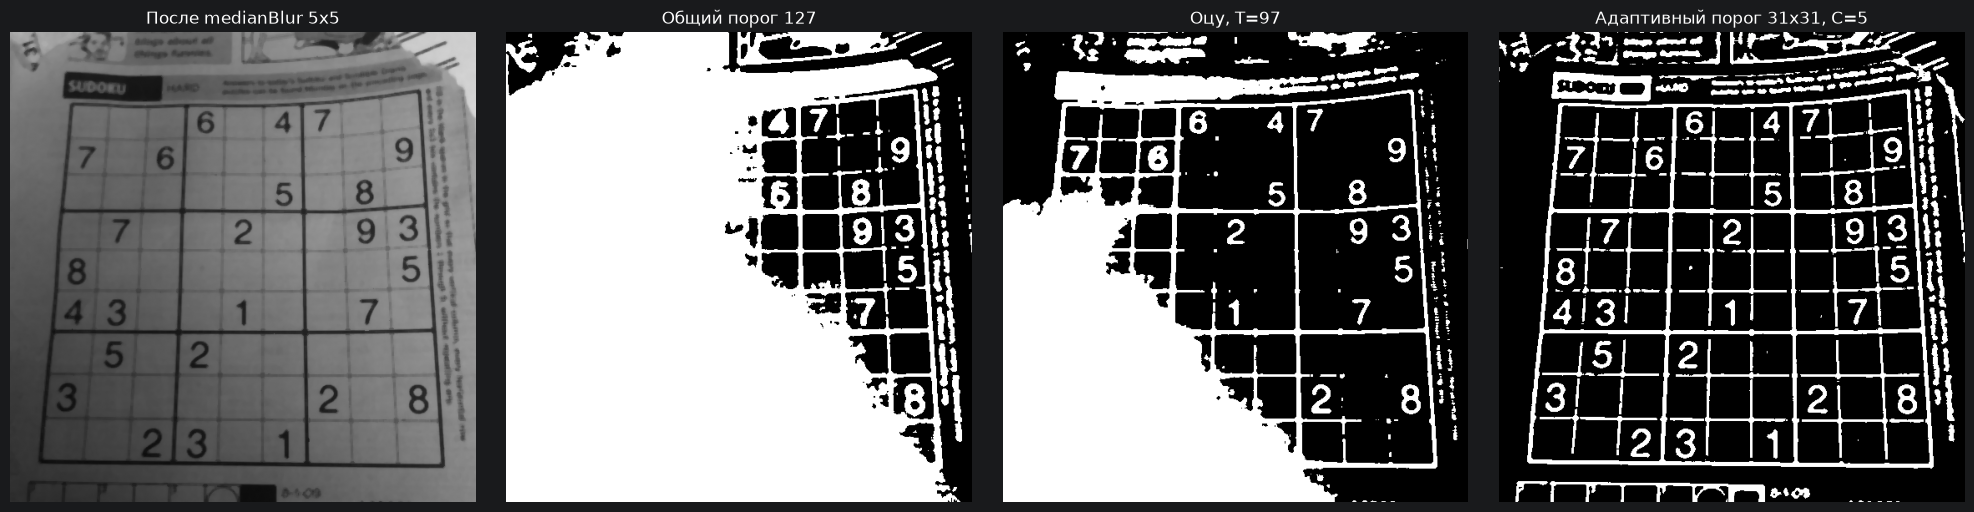

In [10]:
filtered = cv.medianBlur(impulse_noisy, 5)

_, global_mask = cv.threshold(filtered, 127, 255, cv.THRESH_BINARY_INV)
otsu_T, otsu_mask = cv.threshold(filtered, 0, 255, cv.THRESH_BINARY_INV | cv.THRESH_OTSU)
adaptive_mask = cv.adaptiveThreshold(
    filtered, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, 31, 5)

print(f"Порог Оцу: {otsu_T:g}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, image) in zip(axes, [
        ("После medianBlur 5x5", filtered),
        ("Общий порог 127", global_mask),
        (f"Оцу, T={otsu_T:g}", otsu_mask),
        ("Адаптивный порог 31x31, C=5", adaptive_mask)]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Морфологическая очистка

Структурный элемент 3x3 из единиц задаёт соседей операции; это не ядро усреднения,
делить его элементы на девять не нужно. Эрозия сужает белые области, дилатация расширяет;
открытие = эрозия + дилатация, закрытие — в обратном порядке.

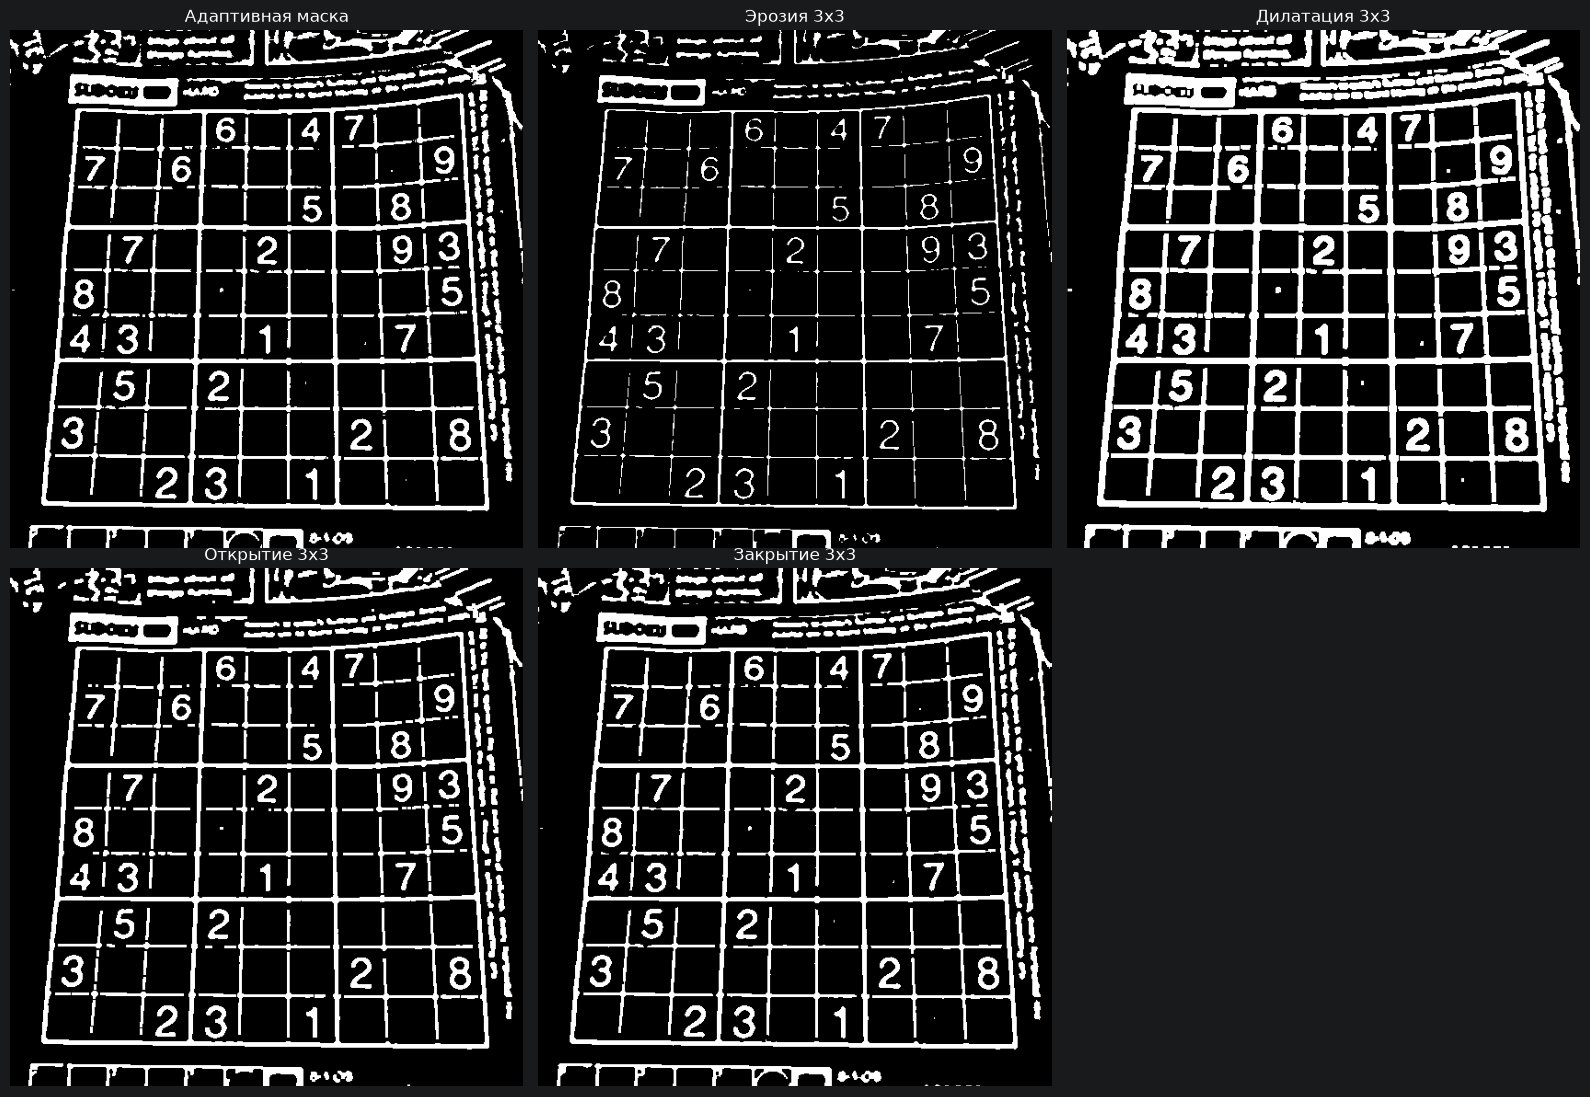

In [11]:
kernel = np.ones((3, 3), np.uint8)
eroded = cv.erode(adaptive_mask, kernel)
dilated = cv.dilate(adaptive_mask, kernel)
opened = cv.morphologyEx(adaptive_mask, cv.MORPH_OPEN, kernel)
closed = cv.morphologyEx(adaptive_mask, cv.MORPH_CLOSE, kernel)

morphology = {
    "Адаптивная маска": adaptive_mask,
    "Эрозия 3x3": eroded,
    "Дилатация 3x3": dilated,
    "Открытие 3x3": opened,
    "Закрытие 3x3": closed,
}

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, (title, image) in zip(axes.flat, morphology.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Проверим конкретный небольшой фрагмент крупнее: видно, исчезли ли лишние белые точки,
соединились ли разорванные линии и не слились ли соседние штрихи.

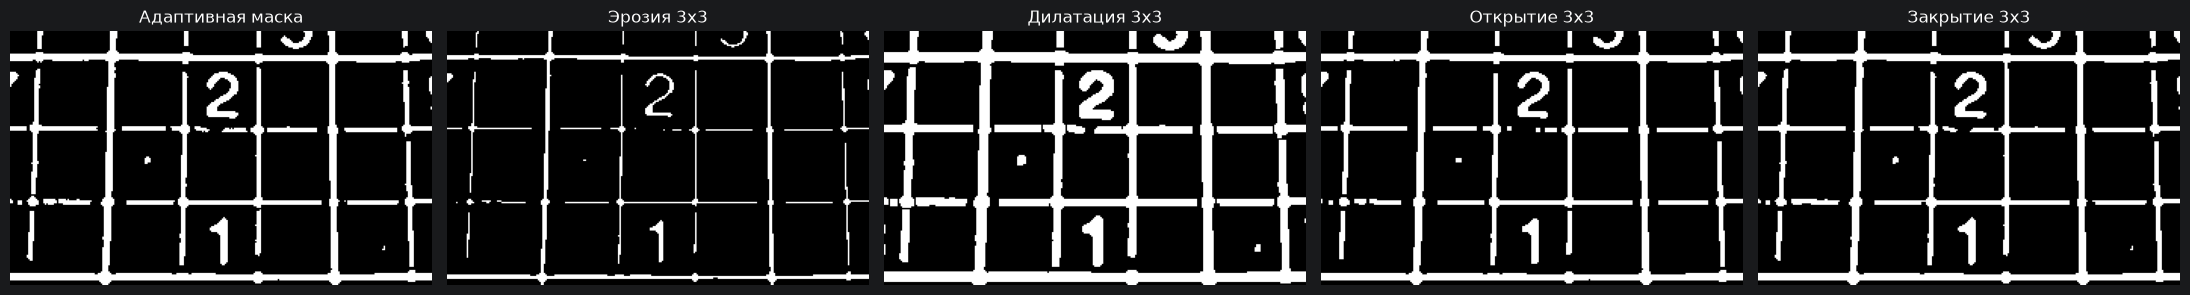

True

In [12]:
y0, y1 = int(height * 0.35), int(height * 0.65)
x0, x1 = int(width * 0.25), int(width * 0.75)

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, (title, image) in zip(axes, morphology.items()):
    ax.imshow(image[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

cv.imwrite(str(OUT / "adaptive_mask.png"), adaptive_mask)
cv.imwrite(str(OUT / "erosion.png"), eroded)
cv.imwrite(str(OUT / "dilation.png"), dilated)
cv.imwrite(str(OUT / "opening.png"), opened)
cv.imwrite(str(OUT / "closing.png"), closed)

## 10. Выбор окончательной маски

Сколько пикселей меняет каждая операция относительно адаптивной маски:

In [13]:
for name, image in (("Открытие", opened), ("Закрытие", closed)):
    removed = np.count_nonzero((adaptive_mask == 255) & (image == 0))
    added = np.count_nonzero((adaptive_mask == 0) & (image == 255))
    components_before = cv.connectedComponents(adaptive_mask)[0] - 1
    components_after = cv.connectedComponents(image)[0] - 1
    print(f"{name}: удалено {removed}, добавлено {added} пикселей; "
          f"компонент {components_before} → {components_after}")

Открытие: удалено 1802, добавлено 0 пикселей; компонент 254 → 239
Закрытие: удалено 0, добавлено 767 пикселей; компонент 254 → 174


Открытие удаляет мелкие белые точки (компоненты из нескольких пикселей) и оставляет
основные штрихи и цифры на месте. Закрытие ничего не удаляет, но расширяет белые области
и заполняет промежутки в сетке: штрихи утолщаются, а соседние элементы могут слипнуться.

Для окончательной маски выбираем **открытие**: на этой фотографии главный дефект маски —
отдельные светлые крапинки от шума, и именно их убирает открытие, почти не затрагивая цифры.
Закрытие полезно было бы, если бы линии были разорваны, но здесь разрывов немного,
а утолщение штрихов мешает дальнейшему анализу.

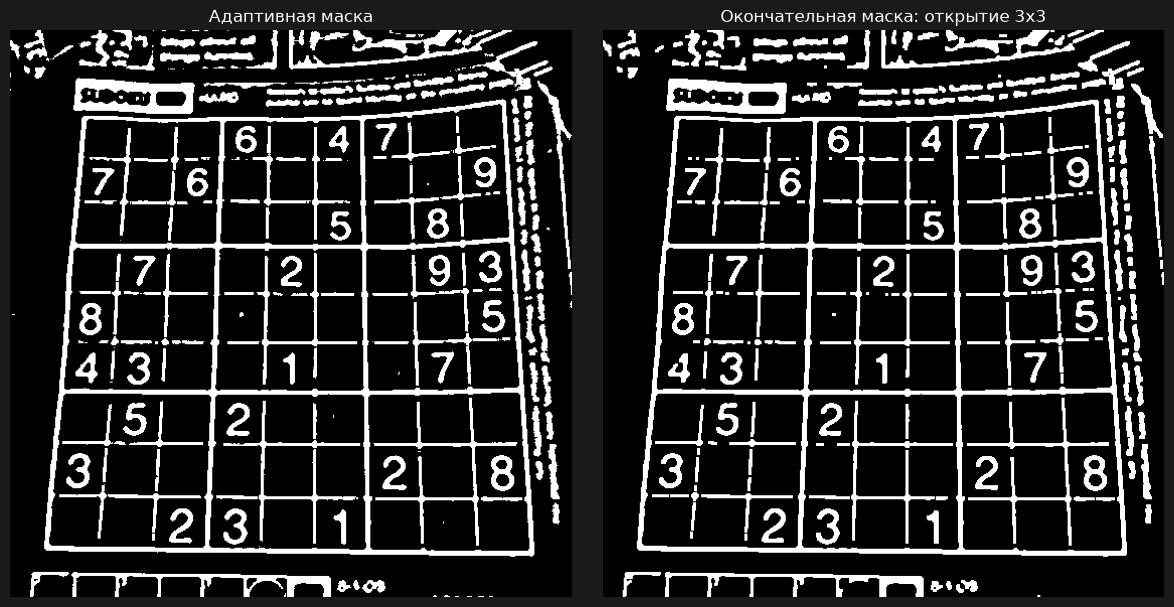

Сохранено в: /home/er1ta1n/kubsu/course_4/multimedia/lab3/results


In [14]:
final_mask = opened
cv.imwrite(str(OUT / "final_mask.png"), final_mask)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (title, image) in zip(axes, [("Адаптивная маска", adaptive_mask),
                                     ("Окончательная маска: открытие 3x3", final_mask)]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Сохранено в:", OUT.resolve())